<a href="https://colab.research.google.com/github/KaterynaKon/irish-tender-value/blob/main/public_tender_value.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Estimating the Expected Contract Value of Irish Public Construction Tenders

## Phase 1 - Business Understanding

### Context and problem

Ireland's public sector buys construction work through competitive tenders: public bodies advertise their projects on the eTenders platform, and contractors submit priced bids by a deadline. A single bid requires weeks of estimator and quantity-surveyor time, while dozens of relevant notices may be published in a month, so a regional firm must decide where to invest that effort before the submission deadline.

Construction companies in Ireland lack a tool to estimate the expected contract value of public tenders before submitting a bid. This leads to wasted resources on low-value tenders and missed high-value opportunities.

"Expected contract value" is operationalised as the awarded value: the amount the winning bidder is contracted to be paid.

The project is limited to construction works contracts(CPV code 45), which covers building projects such as housing as well as civil engineering works.

### Stakeholders and users


The tool is used by bid and tender managers in Irish construction firms, who decide each week which published tenders to pursue. The data is supplied by contracting authorities and by the Office of Government Procurement; neither is asked to do anything additional for this project.

| Stakeholder | Role | Interest |
| --- | --- | --- |
| Bid / tender manager | Primary user | A ranked shortlist with an expected value, produced before the submission deadline |
| Estimating team | Prepares the priced bid | Fewer bids prepared for contracts that turn out to be marginal |
| Managing director / owner | Approves bid preparation spend | A predictable pipeline and a revenue forecast |
| Contracting authorities | Supply the data by publishing notices | Correct use of the published record; no additional reporting burden |
| Office of Government Procurement | Publishes the dataset under CC BY 4.0 | Attribution and correct representation of the data |

### Business or practical objective

The objective is to give the bid manager an expected contract value for every live construction tender before the submission deadline, so that estimating effort is directed towards contracts that are worth pursuing. In practice this supports one recurring decision - bid or no-bid - made every week, across dozens of notices, in minutes rather than hours.

Success at the business level means the firm stops preparing bids for contracts far below its target value, and stops overlooking contracts that are worth more than the notice alone suggests. The output is a ranked list with an expected value and a range, used as an input to the decision, not as the decision itself.


### Analytics objective
The task is regression: for each published construction tender, estimate in euros the value of the contract that will eventually be awarded, using only what the notice says. This turns the practical objective into something measurable — an estimate whose error can be checked against tenders that have already been awarded.

The scope is construction works contracts published from 2023.

### Success criteria

Technical: the error must be at least one third lower than that of the baseline model (which forecasts the average contract value for every tender).

Practical: the top 20% of the ranking must capture at least 50% of the total contract value, and a typical prediction must be within 40% of the true value.

### Constraints and assumptions

Data: public open dataset only - no internal documents, bid prices or company cost data.

Awarded tenders only: the model predicts the value of a contract that is actually awarded, not of a competition that is later cancelled.

Money: values in euro as recorded in the award year; some may exclude VAT, and some may cover framework agreements with multiple call-offs.

Inflation: not adjusted for. The publication year is kept as a feature, so the model can learn each period's price level. Adjusting to constant prices is possible later.

## Phase 2: Data Understanding

### Initial Data Collection Report

| Item | Detail |
| --- | --- |
| Dataset | Public Procurement Opendata Dataset — Contract Notices Published on eTenders |
| Publisher | Office of Government Procurement (Ireland) |
| Source | https://data.gov.ie/dataset/contract-notices-published-on-etenders |
| Licence | Creative Commons Attribution 4.0 (CC BY 4.0) |
| Coverage | Competitions published 01/01/2013 – 30/09/2026 |
| Unit of analysis | One published tender competition |
| Accessed | 6 November 2026 |

Files acquired: one CSV file with 31 columns. No other tables are used and no joins are required.

### Data Description Report

In [7]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:


df = pd.read_csv("/content/drive/MyDrive/data/Public_Procurement_Opendata_Dataset.csv", encoding="cp1252", low_memory=False)
print("rows:", df.shape[0], "columns:", df.shape[1])
df.head()




rows: 87427 columns: 31


,Tender ID,Parent Agreement ID,Contracting Authority,Name of Client Contracting Authority,Agreement Owner,Tender/Contract Name,Notice Published Date / Contract Created Date,Directive,Competition Type,Main Cpv Code,...,Award Published,Sum of Awarded Value (€),Sum of No of Bids Received,Sum of No of SMEs Bids Received,Awarded Suppliers,Sum of No of Awarded SMEs,TED Notice Link,TED CAN Link,Platform,Source
0,6671287.0,3502944.0,The Office of Government Procurement,An Garda Síochána,The Office of Government Procurement,IPS017F-01-004-PROJ000010668-SRFT for External...,30/06/2026,Classic,FW - Mini-Comp,72000000.0,...,30/06/2026,13470600.0,NaN,NaN,Ergo,0.0,NaN,NaN,ED Platform,OpenData-Contracts
1,7249646.0,4574076.0,The Office of Government Procurement,Houses of the Oireachtas Service,The Office of Government Procurement,ITC016F-01-009 SRFT for Network Products and A...,30/06/2026,Classic,FW - Mini-Comp,32410000.0,...,30/06/2026,1922671.0,NaN,NaN,Vodafone,0.0,NaN,NaN,ED Platform,OpenData-Contracts
2,7289488.0,2624317.0,The Office of Government Procurement,Dublin and Dun Laoghaire Education and Trainin...,The Office of Government Procurement,SRFT for Lift and Escalator Maintenance for Du...,30/06/2026,Classic,FW - Mini-Comp,42400000.0,...,30/06/2026,203015.0,NaN,NaN,Orona MID WESTERN LIFTS,1.0,NaN,NaN,ED Platform,OpenData-Contracts
3,7519112.0,1886457.0,Tipperary County Council,NaN,Tipperary County Council,Tipperary County Council - Refurbishment Works...,30/06/2026,Classic,FW - Mini-Comp,45000000.0,...,30/06/2026,28790.0,NaN,NaN,J and S Cahalan Builders LTD,1.0,NaN,NaN,ED Platform,OpenData-Contracts
4,7558528.0,1794066.0,Health Service Executive (HSE),NaN,The Office of Government Procurement,HSE 28286 - Provision of Business Management C...,30/06/2026,Classic,FW - Mini-Comp,72000000.0,...,25/06/2026,3019896.0,NaN,NaN,Grant Thornton,0.0,NaN,NaN,ED Platform,OpenData-Contracts


**Encoding**
 The dataset is distributed in cp1252, not UTF-8. Reading it with the default UTF-8 codec fails immediately on the header, because the euro sign € is byte 0x80 in cp1252, which is not a valid UTF-8 start byte. Consequence: all text fields must be read with an explicit encoding="cp1252";


The dataset has 87,427 rows and 31 columns. One row is one published tender competition: a single notice published by one contracting authority, with its own CPV code, its own procedure and, where an award notice exists, its recorded contract value.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87427 entries, 0 to 87426
Data columns (total 31 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Tender ID                                      83517 non-null  float64
 1   Parent Agreement ID                            3719 non-null   float64
 2   Contracting Authority                          87394 non-null  object 
 3   Name of Client Contracting Authority           9505 non-null   object 
 4   Agreement Owner                                3719 non-null   object 
 5   Tender/Contract Name                           87427 non-null  object 
 6   Notice Published Date / Contract Created Date  85884 non-null  object 
 7   Directive                                      31079 non-null  object 
 8   Competition Type                               87427 non-null  object 
 9   Main Cpv Code                                  356

Dates arrive as text and must be converted before use, money is already numeric, and the remaining 22 columns are text — free-text titles, category labels and identifiers.


In [10]:
df.isna().sum().sort_values(ascending=False).head(10)




,0
Parent Agreement ID,83708
Agreement Owner,83708
Cancelled Date,82904
Name of Client Contracting Authority,77922
TED CAN Link,70718
Evaluation Type,62668
TED Notice Link,59399
Sum of Awarded Value (€),56737
Directive,56348
Sum of Notice Estimated Value (€),55911


Tender ID identifies a competition but is not unique in the file, so it cannot be used as an input.


Candidate inputs: CPV code, contracting authority, contract type, threshold level, procedure, contract duration, publication date and the words in the notice title. All are known when the notice is published.

### Data Exploration Report

Exploration is carried out on a working subset of twelve columns chosen for the analysis. The full file is retained and described above.

In [11]:
keep = [
    "Tender ID",
    "Contracting Authority",
    "Tender/Contract Name",
    "Notice Published Date / Contract Created Date",
    "Main Cpv Code",
    "Contract Type",
    "Threshold Level",
    "Procedure",
    "Sum of Notice Estimated Value (€)",
    "Sum of Contract Duration (Months)",
    "Award Published",
    "Sum of Awarded Value (€)",
]
d = df[keep].copy()
d.shape
d.head()

,Tender ID,Contracting Authority,Tender/Contract Name,Notice Published Date / Contract Created Date,Main Cpv Code,Contract Type,Threshold Level,Procedure,Sum of Notice Estimated Value (€),Sum of Contract Duration (Months),Award Published,Sum of Awarded Value (€)
0,6671287.0,The Office of Government Procurement,IPS017F-01-004-PROJ000010668-SRFT for External...,30/06/2026,72000000.0,NaN,Direct Invite,Direct Invite – Mini-Competition,NaN,48.0,30/06/2026,13470600.0
1,7249646.0,The Office of Government Procurement,ITC016F-01-009 SRFT for Network Products and A...,30/06/2026,32410000.0,NaN,Direct Invite,Direct Invite – Mini-Competition,NaN,60.0,30/06/2026,1922671.0
2,7289488.0,The Office of Government Procurement,SRFT for Lift and Escalator Maintenance for Du...,30/06/2026,42400000.0,NaN,Direct Invite,Direct Invite – Mini-Competition,NaN,36.0,30/06/2026,203015.0
3,7519112.0,Tipperary County Council,Tipperary County Council - Refurbishment Works...,30/06/2026,45000000.0,NaN,Direct Invite,Direct Invite – Mini-Competition,NaN,2.0,30/06/2026,28790.0
4,7558528.0,Health Service Executive (HSE),HSE 28286 - Provision of Business Management C...,30/06/2026,72000000.0,NaN,Direct Invite,Direct Invite – Mini-Competition,NaN,18.0,25/06/2026,3019896.0


Appropriate frequencies, proportions and descriptive statistics.

In [25]:
counts = d["Contract Type"].value_counts(dropna=False)
share = d["Contract Type"].value_counts(normalize=True, dropna=False).mul(100).round(1)
pd.DataFrame({"count": counts, "share_%": share})



,count,share_%
Contract Type,,
Services,39441,45.1
Supplies,16941,19.4
Works,16270,18.6
NaN,13341,15.3
Work Related Services,1434,1.6


Services are the largest group, with 45.1% of all notices. Supplies are 19.4% and works are 18.6%. So construction is only a small part of the file, and that is why the analysis keeps works only. 15.3% of the rows have no contract type, so this column alone cannot define the scope; the CPV code is the main filter. Design and consultancy work is only 1.6%, so it is left out.
 переклади

In [24]:
counts = d["Threshold Level"].value_counts(dropna=False)
share = d["Threshold Level"].value_counts(normalize=True, dropna=False).mul(100).round(1)
pd.DataFrame({"count": counts, "share_%": share})

,count,share_%
Threshold Level,,
National,47125,53.9
OJEU,25661,29.4
Direct Invite,13098,15.0
NaN,1543,1.8


Most notices are National (53.9%), followed by OJEU (29.4%) and Direct Invite (15.0%). The "Threshold level" field has almost no missing values (1.8%), so it is reliable; it indirectly reflects contract size and how open the competition is, so it is likely to be useful for the price model - but whether it actually affects price still needs to be tested, not assumed.


In [26]:
counts = d["Procedure"].value_counts(dropna=False)
share = d["Procedure"].value_counts(normalize=True, dropna=False).mul(100).round(1)
pd.DataFrame({"count": counts, "share_%": share})


,count,share_%
Procedure,,
Open Procedure,62815,71.8
Direct Invite – Mini-Competition,9877,11.3
Competitive Procedure With Negotiation,4144,4.7
Restricted Procedure,3995,4.6
NaN,3915,4.5
Simplified,652,0.7
DPS Qualification,621,0.7
Competitive Dialogue,551,0.6
Negotiated Procedure Without Prior Publication,377,0.4


Open Procedure accounts for 71.8% of all notices, so this field mostly separates open competition from everything else. Seven categories have less than 1% each - from Simplified (0.8%) down to Direct Invite - Quick Quote (0.2%) - and are too rare to learn from, so they will be grouped as Other in Data Preparation. 4.5% of rows are missing, more than for Threshold Level. Direct Invite appears in both this field and Threshold Level, so the two overlap and only one may be needed in the model.

In [20]:
cpv = pd.to_numeric(d["Main Cpv Code"], errors="coerce")
d["cpv2"] = (cpv // 1_000_000).astype("Int64")
d["cpv2"].value_counts(dropna=False).head(15)

,count
cpv2,
<NA>,51767
45,6949
71,4366
79,3150
72,2421
15,1783
34,1454
48,1143
80,990


The CPV code is missing for 51,767 rows, and construction work (division 45) is the largest division only among the rows where the code exists. A field missing in more than half the file is unlikely to be missing at random, so its coverage over time is checked next.


Dates are stored as text in dd/mm/yyyy format. The year is extracted because the analysis needs the publication year, not the full date.

In [22]:
d["year"] = pd.to_datetime(
    d["Notice Published Date / Contract Created Date"],
    format="%d/%m/%Y",
    errors="coerce"
).dt.year


In [23]:
d.groupby("year")["Main Cpv Code"].apply(lambda s: round(s.isna().mean() * 100, 1))


,Main Cpv Code
year,
2013.0,74.9
2014.0,72.0
2015.0,78.6
2016.0,83.0
2017.0,86.2
2018.0,87.1
2019.0,89.4
2020.0,87.9
2021.0,89.3


Coverage is not constant over time. The CPV code is missing for 75-89% of notices published between 2013 and 2022, but for 42% in 2023 and under 2% from 2024. The awarded value follows the same pattern, rising from 2.2% of notices in 2013 to 56% in 2024. The gap reflects a change in what was published, not a property of individual tenders.


Decision: the analysis is limited to notices published from 2023 onwards, because before that year the target and the classification are largely absent. This leaves 1,880 works contracts with a recorded value, against 2,869 for the full period.


 #### Descriptive statistics

The analysis set keeps only works contracts that have a recorded awarded value and were published from 2023 onwards. The three conditions follow from the scope and from the coverage findings described in the data quality section.


In [28]:
awd = "Sum of Awarded Value (€)"
has = d[awd].gt(0)
works = d["Contract Type"].eq("Works")

a = d[works & has & (d["year"] >= 2023)].copy()
print("rows in analysis set:", len(a))

rows in analysis set: 1715


In [29]:
a[["Sum of Awarded Value (€)", "Sum of Notice Estimated Value (€)",
   "Sum of Contract Duration (Months)"]].describe()


,Sum of Awarded Value (€),Sum of Notice Estimated Value (€),Sum of Contract Duration (Months)
count,1.715000e+03,1.255000e+03,1584.000000
mean,2.283566e+07,2.516175e+07,14.882576
std,2.093325e+08,2.068275e+08,19.439950
min,1.000000e+00,0.000000e+00,0.000000
25%,1.894865e+05,1.500000e+05,4.000000
50%,5.147220e+05,5.000000e+05,11.500000
75%,2.239228e+06,2.860000e+06,18.000000
max,4.500000e+09,4.500000e+09,360.000000


This table summarises the three numeric variables: how many values are present, the mean, the standard deviation, the quartiles and the extremes. It is the first view of the target and shows how far the mean lies from the median.


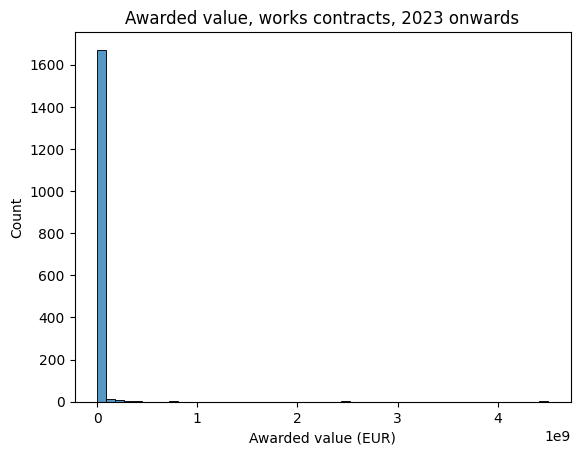

In [32]:
sns.histplot(a["Sum of Awarded Value (€)"], bins=50)
plt.title("Awarded value, works contracts, 2023 onwards")
plt.xlabel("Awarded value (EUR)")
plt.show()

The awarded value is heavily skewed. The median contract is worth €515k, while the mean is €22.8M - 44 times larger - and the standard deviation exceeds the mean. A small number of very large contracts therefore dominates any average, which is why the median describes the typical tender better than the mean, and why the target will be modelled on a logarithmic scale. Two values need checking before modelling: a minimum of €1 and a maximum of €4.5bn


In [33]:
print("value = 1:", (a["Sum of Awarded Value (€)"] == 1).sum())
print("value = 4.5e9:", (a["Sum of Awarded Value (€)"] == 4.5e9).sum())
print("duration = 0:", (a["Sum of Contract Duration (Months)"] == 0).sum())
print("duration = 360:", (a["Sum of Contract Duration (Months)"] == 360).sum())

value = 1: 8
value = 4.5e9: 2
duration = 0: 2
duration = 360: 1


Two extreme values look like placeholders rather than real prices: eight contracts carry an awarded value of €1 and two carry €4.5bn, together 0.6% of the analysis set. Two contracts have a duration of zero and one has 360 months. The ten placeholder values will be removed in Data Preparation, and a duration of zero will be treated as missing rather than as a very short contract.


In [37]:
a.groupby("Threshold Level")["Sum of Awarded Value (€)"].agg(["count", "median"])


,count,median
Threshold Level,,
National,1357,395200.000
OJEU,358,8191035.885


In [35]:
a.groupby("year")["Sum of Awarded Value (€)"].median()


,Sum of Awarded Value (€)
year,
2023.0,600000.000
2024.0,594427.750
2025.0,455930.445
2026.0,327855.500


Threshold level separates contract size sharply  the median OJEU award (€8.19M) is about twenty times the median National award (€395k)  so the field carries a strong signal for the model. The analysis set contains 1,357 National and 358 OJEU contracts, and no Direct Invite contracts at all, because their awarded value is not published. The median award falls from €600k in 2023 to €328k in 2026, but 2026 is incomplete: awards for large contracts are published later, so the fall reflects publication timing rather than a change in prices.


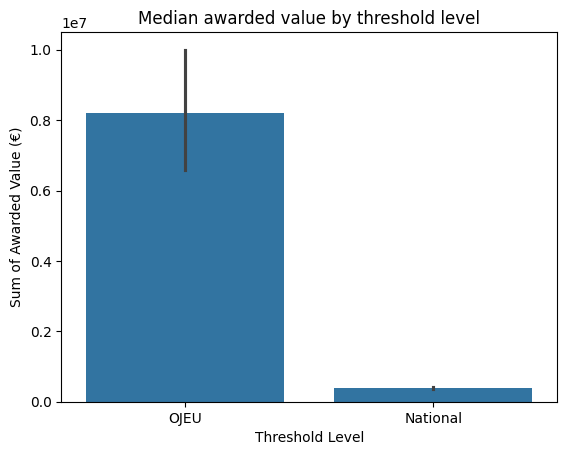

In [38]:
sns.barplot(data=a, x="Threshold Level", y="Sum of Awarded Value (€)", estimator="median")
plt.title("Median awarded value by threshold level")
plt.show()


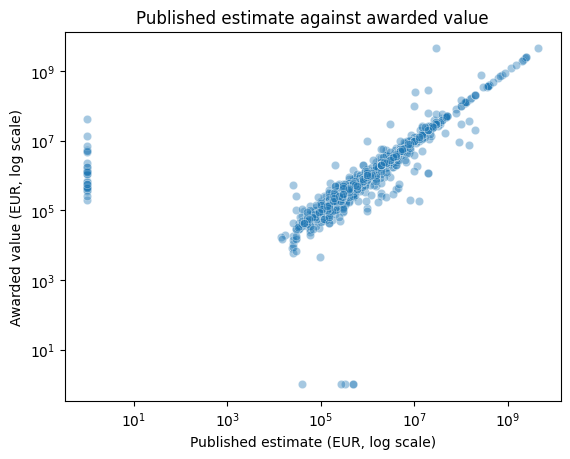

In [39]:
sns.scatterplot(data=a, x="Sum of Notice Estimated Value (€)", y="Sum of Awarded Value (€)", alpha=0.4)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Published estimate (EUR, log scale)")
plt.ylabel("Awarded value (EUR, log scale)")
plt.title("Published estimate against awarded value")
plt.show()


The published estimate and the awarded value lie close to the diagonal, so the estimate is a strong predictor of the final contract value and should be used as a feature rather than ignored. Two clusters sit away from the diagonal: a vertical line at an estimate of €1, where the awarded value varies widely, and a horizontal line at an awarded value of €1. Both are placeholders and must be treated as missing rather than as real prices. Because the estimate is absent for about a quarter of the analysis set, it will be used together with a flag marking where it is missing, and accuracy will be reported separately for notices with and without a published estimate.


### Data Quality Report

In [13]:
d.nunique()

,0
Tender ID,83273
Contracting Authority,5931
Tender/Contract Name,82555
Notice Published Date / Contract Created Date,4302
Main Cpv Code,2964
Contract Type,4
Threshold Level,3
Procedure,10
Sum of Notice Estimated Value (€),3361
Sum of Contract Duration (Months),126
